# Equidade das predicoes de obito entre subgrupos demograficos, teste de 2024

Este notebook avalia se a capacidade dos cinco algoritmos de discriminar o risco de obito por chikungunya varia entre subgrupos demograficos do teste de 2024.
As variaveis de estratificacao sao sexo, raca ou cor, e faixa etaria, as tres colunas demograficas usadas aqui a partir de `data/features/baseline/X_test.parquet`.
Para cada subgrupo e cada um dos cinco algoritmos ja treinados na fase de modelagem, a AUPRC e o ROC-AUC sao recalculados apenas sobre os casos daquele subgrupo, a partir das probabilidades preditas ja salvas em `output/metricas/`.
A diferenca entre a metrica de um subgrupo e a do subgrupo de referencia da mesma variavel, chamada aqui de delta AUPRC e delta ROC-AUC, e a medida central usada para comparar a equidade do desempenho do modelo entre subgrupos.
Subgrupos com menos de 10 obitos no teste de 2024 tem a AUPRC e o ROC-AUC marcados como amostra insuficiente, em vez de um numero, porque as duas metricas ficam instaveis quando calculadas sobre poucos eventos positivos.
Este notebook reporta apenas os numeros observados nos cinco algoritmos sobre o teste de 2024, sem nenhuma comparacao com valores de referencia externos a este estudo.

Importa as bibliotecas necessarias, define os diretorios de entrada e saida, e fixa a lista dos cinco algoritmos e o limiar minimo de obitos por subgrupo usado ao longo do notebook.
As tabelas de metricas por subgrupo sao salvas em `analysis/results_equidade/`, e os graficos de delta AUPRC sao salvos em `analysis/plots/equidade/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import average_precision_score, roc_auc_score

pd.set_option("display.max_rows", 100)

PROJECT_ROOT = Path.cwd().parent.parent
DIRETORIO_FEATURES = PROJECT_ROOT / "data" / "features" / "baseline"
DIRETORIO_METRICAS = PROJECT_ROOT / "output" / "metricas"
DIRETORIO_RESULTADOS_ANALISE = PROJECT_ROOT / "analysis" / "results_equidade"
DIRETORIO_PLOTS = PROJECT_ROOT / "analysis" / "plots" / "equidade"
DIRETORIO_RESULTADOS_ANALISE.mkdir(parents=True, exist_ok=True)
DIRETORIO_PLOTS.mkdir(parents=True, exist_ok=True)

ALGORITMOS = ["regressao_logistica", "arvore_decisao", "random_forest", "xgboost", "lightgbm"]
LIMIAR_OBITOS_MINIMO = 10

Carrega as tres colunas demograficas do teste de 2024 a partir de `data/features/baseline/X_test.parquet`: sexo, raca ou cor, e idade em anos.
A idade em anos e convertida em cinco faixas etarias fixas, menor que 1 ano, de 1 a 17 anos, de 18 a 39 anos, de 40 a 59 anos, e 60 anos ou mais, a terceira variavel de estratificacao usada neste notebook.
Um caso sem idade registrada fica sem faixa etaria definida e e naturalmente excluido das tabelas por faixa etaria mais adiante, da mesma forma que os dois casos com sexo igual a "I", ignorado, sao excluidos da comparacao por sexo por serem uma amostra irrelevante.

In [2]:
COLUNAS_DEMOGRAFICAS = ["CS_SEXO", "CS_RACA", "IDADE_ANOS"]
LIMITES_FAIXA_ETARIA = [0, 1, 18, 40, 60, 105]
ROTULOS_FAIXA_ETARIA = ["<1", "1-17", "18-39", "40-59", "60+"]

covariaveis_teste2024 = pd.read_parquet(
    DIRETORIO_FEATURES / "X_test.parquet", columns=COLUNAS_DEMOGRAFICAS
).reset_index(drop=True)
covariaveis_teste2024["faixa_etaria"] = pd.cut(
    covariaveis_teste2024["IDADE_ANOS"],
    bins=LIMITES_FAIXA_ETARIA,
    labels=ROTULOS_FAIXA_ETARIA,
    right=False,
)

numero_registros_sem_faixa_etaria = covariaveis_teste2024["faixa_etaria"].isna().sum()
covariaveis_teste2024.shape, numero_registros_sem_faixa_etaria

((3978, 4), np.int64(1))

Carrega, para cada um dos cinco algoritmos, as predicoes de probabilidade e o alvo real de obito ja salvos pela fase de modelagem para o teste de 2024.
Confirma que o alvo real e identico entre os cinco arquivos e que o numero de registros coincide com o das colunas demograficas carregadas na celula anterior, ja que ambos vem do mesmo conjunto de teste na mesma ordem posicional.
Concatena, para cada algoritmo, a tabela de predicoes com as colunas demograficas pela posicao da linha, criando uma unica tabela por algoritmo usada no restante do notebook.

In [3]:
predicoes_teste2024 = {
    algoritmo: pd.read_parquet(
        DIRETORIO_METRICAS / f"{algoritmo}_predicoes_teste2024.parquet"
    ).reset_index(drop=True)
    for algoritmo in ALGORITMOS
}

numero_registros_covariaveis = len(covariaveis_teste2024)
alvo_real_teste2024 = predicoes_teste2024[ALGORITMOS[0]]["obito"].to_numpy()
for algoritmo in ALGORITMOS:
    assert len(predicoes_teste2024[algoritmo]) == numero_registros_covariaveis
    assert np.array_equal(predicoes_teste2024[algoritmo]["obito"].to_numpy(), alvo_real_teste2024)

predicoes_com_covariaveis = {
    algoritmo: pd.concat([predicoes_teste2024[algoritmo], covariaveis_teste2024], axis=1)
    for algoritmo in ALGORITMOS
}

numero_registros_covariaveis, int(alvo_real_teste2024.sum())

(3978, 208)

Define as tres variaveis de estratificacao analisadas neste notebook, sexo, raca ou cor, e faixa etaria, cada uma com seus subgrupos validos, os rotulos legiveis de cada subgrupo, e o subgrupo de referencia usado no calculo do delta.
O subgrupo de referencia e feminino para sexo, branca para raca ou cor, e a faixa de 18 a 39 anos para faixa etaria, a faixa com a menor prevalencia observada de obito entre as cinco faixas.
O codigo 9 de raca ou cor, rotulado ignorado, nao representa uma categoria racial e e mantido na tabela apenas para registro e transparencia, nunca como parte da comparacao de equidade entre racas.

In [4]:
ROTULOS_RACA_COR = {
    "1": "Branca",
    "2": "Preta",
    "3": "Amarela",
    "4": "Parda",
    "5": "Indigena",
    "9": "Ignorado",
}

ESPECIFICACOES_ESTRATIFICACAO = [
    {
        "variavel_estratificacao": "sexo",
        "rotulo_variavel": "sexo",
        "coluna": "CS_SEXO",
        "subgrupos": ["F", "M"],
        "rotulos_subgrupo": {"F": "Feminino", "M": "Masculino"},
        "subgrupo_referencia": "F",
    },
    {
        "variavel_estratificacao": "raca_cor",
        "rotulo_variavel": "raca ou cor",
        "coluna": "CS_RACA",
        "subgrupos": ["1", "2", "3", "4", "5", "9"],
        "rotulos_subgrupo": ROTULOS_RACA_COR,
        "subgrupo_referencia": "1",
    },
    {
        "variavel_estratificacao": "faixa_etaria",
        "rotulo_variavel": "faixa etaria",
        "coluna": "faixa_etaria",
        "subgrupos": ROTULOS_FAIXA_ETARIA,
        "rotulos_subgrupo": {rotulo: rotulo for rotulo in ROTULOS_FAIXA_ETARIA},
        "subgrupo_referencia": "18-39",
    },
]

[especificacao["variavel_estratificacao"] for especificacao in ESPECIFICACOES_ESTRATIFICACAO]

['sexo', 'raca_cor', 'faixa_etaria']

Para cada variavel de estratificacao, cada algoritmo e cada subgrupo, calcula o numero de casos, o numero de obitos, a prevalencia observada de obito, a AUPRC e o ROC-AUC restritos aos casos daquele subgrupo.
A AUPRC e o ROC-AUC sao calculados com `average_precision_score` e `roc_auc_score` do scikit-learn, sobre a probabilidade predita e o desfecho real daquele algoritmo, apenas nas linhas do subgrupo em questao.
Subgrupos com menos de 10 obitos recebem o texto amostra insuficiente nas colunas de AUPRC e ROC-AUC, em vez de um valor numerico, porque essas duas metricas exigem uma quantidade razoavel de eventos positivos para ser estimadas de forma estavel.

In [5]:
linhas_metricas_subgrupo = []
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    for algoritmo in ALGORITMOS:
        tabela_algoritmo = predicoes_com_covariaveis[algoritmo]
        for subgrupo in especificacao["subgrupos"]:
            tabela_filtrada = tabela_algoritmo.loc[tabela_algoritmo[especificacao["coluna"]] == subgrupo]
            numero_registros = len(tabela_filtrada)
            numero_obitos = int(tabela_filtrada["obito"].sum())

            if numero_obitos < LIMIAR_OBITOS_MINIMO:
                auprc_subgrupo = "amostra insuficiente"
                roc_auc_subgrupo = "amostra insuficiente"
            else:
                auprc_subgrupo = average_precision_score(
                    tabela_filtrada["obito"], tabela_filtrada["probabilidade_predita"]
                )
                roc_auc_subgrupo = roc_auc_score(
                    tabela_filtrada["obito"], tabela_filtrada["probabilidade_predita"]
                )

            linhas_metricas_subgrupo.append(
                {
                    "variavel_estratificacao": especificacao["variavel_estratificacao"],
                    "subgrupo": especificacao["rotulos_subgrupo"][subgrupo],
                    "algoritmo": algoritmo,
                    "n": numero_registros,
                    "obitos": numero_obitos,
                    "prevalencia_obito": numero_obitos / numero_registros,
                    "auprc": auprc_subgrupo,
                    "roc_auc": roc_auc_subgrupo,
                }
            )

tabela_metricas_subgrupo = pd.DataFrame(linhas_metricas_subgrupo)
tabela_metricas_subgrupo

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc
0,sexo,Feminino,regressao_logistica,2196,90,0.040984,0.225853,0.840577
1,sexo,Masculino,regressao_logistica,1780,118,0.066292,0.233473,0.79349
2,sexo,Feminino,arvore_decisao,2196,90,0.040984,0.106781,0.729102
3,sexo,Masculino,arvore_decisao,1780,118,0.066292,0.15166,0.756012
4,sexo,Feminino,random_forest,2196,90,0.040984,0.195506,0.823969
5,sexo,Masculino,random_forest,1780,118,0.066292,0.261747,0.794948
6,sexo,Feminino,xgboost,2196,90,0.040984,0.151469,0.75884
7,sexo,Masculino,xgboost,1780,118,0.066292,0.232686,0.761896
8,sexo,Feminino,lightgbm,2196,90,0.040984,0.172766,0.788411
9,sexo,Masculino,lightgbm,1780,118,0.066292,0.220695,0.759782


Lista, de forma explicita, os subgrupos marcados como amostra insuficiente, para deixar claro quais comparacoes de equidade nao podem ser feitas com confianca nesta analise.
Como o numero de obitos de um subgrupo nao depende do algoritmo, cada combinacao de variavel e subgrupo aparece aqui uma unica vez, mesmo tendo sido calculada para os cinco algoritmos na celula anterior.

In [6]:
subgrupos_amostra_insuficiente = (
    tabela_metricas_subgrupo.loc[
        tabela_metricas_subgrupo["auprc"] == "amostra insuficiente",
        ["variavel_estratificacao", "subgrupo", "obitos"],
    ]
    .drop_duplicates()
    .sort_values(["variavel_estratificacao", "obitos"])
    .reset_index(drop=True)
)
subgrupos_amostra_insuficiente

,variavel_estratificacao,subgrupo,obitos
0,faixa_etaria,<1,5
1,faixa_etaria,1-17,6
2,raca_cor,Indigena,0
3,raca_cor,Amarela,2
4,raca_cor,Preta,5
5,raca_cor,Ignorado,9


Salva a tabela de metricas por subgrupo em tres arquivos separados, um por variavel de estratificacao, em `analysis/results_equidade/`, para facilitar a leitura isolada de cada variavel.

In [7]:
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    tabela_metricas_subgrupo.loc[
        tabela_metricas_subgrupo["variavel_estratificacao"] == nome_variavel
    ].to_csv(DIRETORIO_RESULTADOS_ANALISE / f"metricas_por_subgrupo_{nome_variavel}.csv", index=False)

sorted(caminho.name for caminho in DIRETORIO_RESULTADOS_ANALISE.glob("metricas_por_subgrupo_*.csv"))

['metricas_por_subgrupo_faixa_etaria.csv',
 'metricas_por_subgrupo_raca_cor.csv',
 'metricas_por_subgrupo_sexo.csv']

Para cada variavel de estratificacao e cada algoritmo, calcula o delta AUPRC e o delta ROC-AUC de cada subgrupo em relacao ao subgrupo de referencia daquela variavel, subtraindo a metrica do subgrupo de referencia da metrica do subgrupo em questao.
Quando a metrica do subgrupo, a do subgrupo de referencia, ou as duas, estao marcadas como amostra insuficiente, o delta correspondente tambem e marcado como amostra insuficiente, em vez de um valor numerico.
O subgrupo de referencia de cada variavel aparece na tabela final com delta igual a zero, por definicao, servindo de linha de base nos graficos da secao seguinte.

In [8]:
referencias_por_variavel_algoritmo = {}
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    rotulo_referencia = especificacao["rotulos_subgrupo"][especificacao["subgrupo_referencia"]]
    linhas_referencia = tabela_metricas_subgrupo.loc[
        (tabela_metricas_subgrupo["variavel_estratificacao"] == especificacao["variavel_estratificacao"])
        & (tabela_metricas_subgrupo["subgrupo"] == rotulo_referencia)
    ]
    for _, linha_referencia in linhas_referencia.iterrows():
        chave_variavel_algoritmo = (linha_referencia["variavel_estratificacao"], linha_referencia["algoritmo"])
        referencias_por_variavel_algoritmo[chave_variavel_algoritmo] = (
            linha_referencia["auprc"],
            linha_referencia["roc_auc"],
        )


def calcular_delta_metrica(valor_subgrupo, valor_referencia):
    if isinstance(valor_subgrupo, str) or isinstance(valor_referencia, str):
        return "amostra insuficiente"
    return valor_subgrupo - valor_referencia


linhas_consolidadas = []
for _, linha in tabela_metricas_subgrupo.iterrows():
    auprc_referencia, roc_auc_referencia = referencias_por_variavel_algoritmo[
        (linha["variavel_estratificacao"], linha["algoritmo"])
    ]
    linhas_consolidadas.append(
        {
            "variavel_estratificacao": linha["variavel_estratificacao"],
            "subgrupo": linha["subgrupo"],
            "algoritmo": linha["algoritmo"],
            "n": linha["n"],
            "obitos": linha["obitos"],
            "prevalencia_obito": linha["prevalencia_obito"],
            "auprc": linha["auprc"],
            "roc_auc": linha["roc_auc"],
            "delta_auprc": calcular_delta_metrica(linha["auprc"], auprc_referencia),
            "delta_roc_auc": calcular_delta_metrica(linha["roc_auc"], roc_auc_referencia),
        }
    )

tabela_equidade_consolidada = pd.DataFrame(linhas_consolidadas)
tabela_equidade_consolidada

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc,delta_auprc,delta_roc_auc
0,sexo,Feminino,regressao_logistica,2196,90,0.040984,0.225853,0.840577,0.0,0.0
1,sexo,Masculino,regressao_logistica,1780,118,0.066292,0.233473,0.79349,0.00762,-0.047088
2,sexo,Feminino,arvore_decisao,2196,90,0.040984,0.106781,0.729102,0.0,0.0
3,sexo,Masculino,arvore_decisao,1780,118,0.066292,0.15166,0.756012,0.044879,0.02691
4,sexo,Feminino,random_forest,2196,90,0.040984,0.195506,0.823969,0.0,0.0
5,sexo,Masculino,random_forest,1780,118,0.066292,0.261747,0.794948,0.066241,-0.029021
6,sexo,Feminino,xgboost,2196,90,0.040984,0.151469,0.75884,0.0,0.0
7,sexo,Masculino,xgboost,1780,118,0.066292,0.232686,0.761896,0.081217,0.003056
8,sexo,Feminino,lightgbm,2196,90,0.040984,0.172766,0.788411,0.0,0.0
9,sexo,Masculino,lightgbm,1780,118,0.066292,0.220695,0.759782,0.047929,-0.028629


Salva a tabela consolidada de metricas e deltas por subgrupo em `analysis/results_equidade/tabela_equidade_consolidada.csv`, reunindo as tres variaveis de estratificacao numa unica tabela longa, com uma linha por combinacao de variavel, subgrupo e algoritmo.

In [9]:
tabela_equidade_consolidada.to_csv(
    DIRETORIO_RESULTADOS_ANALISE / "tabela_equidade_consolidada.csv", index=False
)
tabela_equidade_consolidada.sort_values(["variavel_estratificacao", "subgrupo", "algoritmo"]).reset_index(
    drop=True
)

,variavel_estratificacao,subgrupo,algoritmo,n,obitos,prevalencia_obito,auprc,roc_auc,delta_auprc,delta_roc_auc
0,faixa_etaria,1-17,arvore_decisao,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
1,faixa_etaria,1-17,lightgbm,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
2,faixa_etaria,1-17,random_forest,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
3,faixa_etaria,1-17,regressao_logistica,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
4,faixa_etaria,1-17,xgboost,846,6,0.007092,amostra insuficiente,amostra insuficiente,amostra insuficiente,amostra insuficiente
5,faixa_etaria,18-39,arvore_decisao,927,18,0.019417,0.044399,0.74291,0.0,0.0
6,faixa_etaria,18-39,lightgbm,927,18,0.019417,0.042209,0.725859,0.0,0.0
7,faixa_etaria,18-39,random_forest,927,18,0.019417,0.051087,0.770383,0.0,0.0
8,faixa_etaria,18-39,regressao_logistica,927,18,0.019417,0.066041,0.75877,0.0,0.0
9,faixa_etaria,18-39,xgboost,927,18,0.019417,0.035579,0.671189,0.0,0.0


Para cada variavel de estratificacao, gera um grafico de barras agrupadas que compara o delta AUPRC dos subgrupos validos entre os cinco algoritmos.
Subgrupos marcados como amostra insuficiente sao omitidos do grafico, por nao terem um valor numerico de delta AUPRC, mas continuam presentes na tabela consolidada salva na celula anterior.
O subgrupo de referencia de cada variavel aparece no grafico com delta AUPRC igual a zero, servindo de linha de base visual.
Os tres graficos sao salvos em `analysis/plots/equidade/`, um arquivo por variavel de estratificacao.

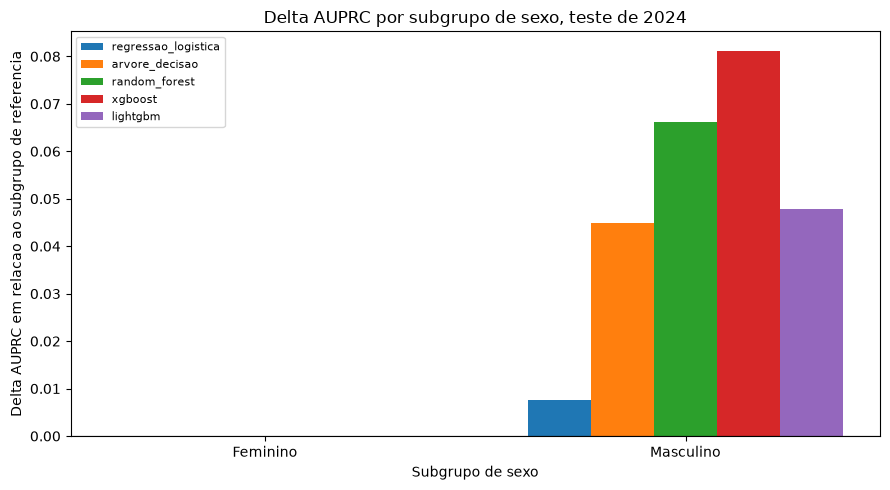

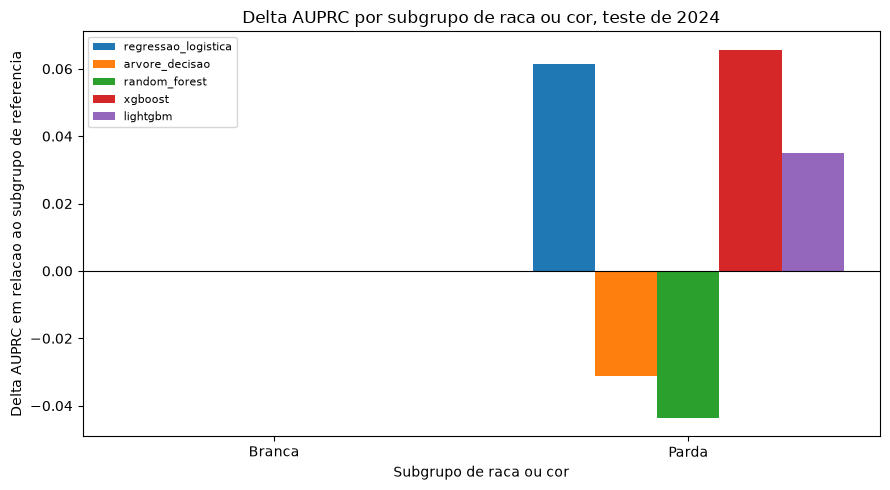

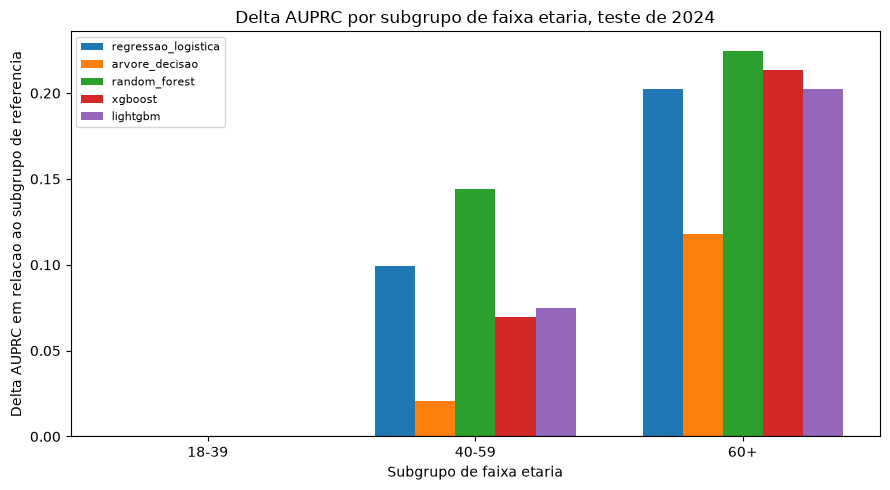

In [10]:
for especificacao in ESPECIFICACOES_ESTRATIFICACAO:
    nome_variavel = especificacao["variavel_estratificacao"]
    rotulo_variavel = especificacao["rotulo_variavel"]
    tabela_variavel = tabela_equidade_consolidada.loc[
        tabela_equidade_consolidada["variavel_estratificacao"] == nome_variavel
    ]
    tabela_variavel_valida = tabela_variavel.loc[
        tabela_variavel["delta_auprc"] != "amostra insuficiente"
    ].copy()
    tabela_variavel_valida["delta_auprc"] = tabela_variavel_valida["delta_auprc"].astype(float)

    ordem_subgrupos = [
        especificacao["rotulos_subgrupo"][subgrupo] for subgrupo in especificacao["subgrupos"]
    ]
    subgrupos_validos = [
        rotulo for rotulo in ordem_subgrupos if rotulo in tabela_variavel_valida["subgrupo"].unique()
    ]

    matriz_delta_auprc = tabela_variavel_valida.pivot(
        index="subgrupo", columns="algoritmo", values="delta_auprc"
    ).loc[subgrupos_validos, ALGORITMOS]

    posicoes_subgrupo = np.arange(len(subgrupos_validos))
    largura_barra = 0.15

    figura, eixo = plt.subplots(figsize=(9, 5))
    for indice_algoritmo, algoritmo in enumerate(ALGORITMOS):
        deslocamento = (indice_algoritmo - (len(ALGORITMOS) - 1) / 2) * largura_barra
        eixo.bar(
            posicoes_subgrupo + deslocamento,
            matriz_delta_auprc[algoritmo],
            width=largura_barra,
            label=algoritmo,
        )

    eixo.axhline(0, color="black", linewidth=0.8)
    eixo.set_xticks(posicoes_subgrupo)
    eixo.set_xticklabels(subgrupos_validos)
    eixo.set_xlabel(f"Subgrupo de {rotulo_variavel}")
    eixo.set_ylabel("Delta AUPRC em relacao ao subgrupo de referencia")
    eixo.set_title(f"Delta AUPRC por subgrupo de {rotulo_variavel}, teste de 2024")
    eixo.legend(loc="best", fontsize=8)
    figura.tight_layout()
    figura.savefig(DIRETORIO_PLOTS / f"delta_auprc_{nome_variavel}.png", dpi=150)
    plt.show()

## Sintese dos achados

Olhando apenas para a AUPRC, dois padroes aparecem de forma consistente nos cinco algoritmos.
O subgrupo Masculino tem AUPRC maior do que o subgrupo Feminino nos cinco algoritmos, com delta AUPRC entre 0,008, na Regressao Logistica, e 0,081, no XGBoost.
A AUPRC tambem cresce de forma consistente com a idade nos cinco algoritmos, menor na faixa de 18 a 39 anos, intermediaria na faixa de 40 a 59 anos, e maior na faixa de 60 anos ou mais, com delta AUPRC da faixa de 60 anos ou mais em relacao a faixa de 18 a 39 anos entre 0,118, na Arvore de Decisao, e 0,225, no Random Forest.

Esses dois padroes coincidem com diferencas grandes de prevalencia observada de obito entre os subgrupos, e a AUPRC tem como piso justamente a prevalencia da classe positiva.
A prevalencia de obito no teste de 2024 e 6,6 por cento no subgrupo Masculino contra 4,1 por cento no subgrupo Feminino, e sobe de 1,9 por cento na faixa de 18 a 39 anos para 4,0 por cento na faixa de 40 a 59 anos e 11,9 por cento na faixa de 60 anos ou mais.
O ROC-AUC nao tem a prevalencia da classe positiva como piso, e mostra um quadro mais misto para sexo, com delta ROC-AUC negativo, pior no subgrupo Masculino, em tres dos cinco algoritmos, Regressao Logistica, Random Forest e LightGBM, e positivo nos outros dois, Arvore de Decisao e XGBoost.
Isso indica que a vantagem de AUPRC do subgrupo Masculino reflete, em boa parte, sua maior prevalencia observada de obito, e nao uma capacidade de discriminacao uniformemente melhor do modelo nesse subgrupo.

Para faixa etaria, o ROC-AUC conta uma historia diferente da AUPRC, e e o unico padrao deste notebook que se mantem consistente nos cinco algoritmos depois de olhar as duas metricas juntas.
O delta ROC-AUC da faixa de 60 anos ou mais em relacao a faixa de 18 a 39 anos e negativo em quatro dos cinco algoritmos, Regressao Logistica, Arvore de Decisao, Random Forest e LightGBM, com o XGBoost como unica excecao positiva.
Ou seja, apesar de ter a AUPRC absoluta mais alta entre as faixas etarias, uma consequencia esperada de sua prevalencia de obito bem maior, o subgrupo de 60 anos ou mais tem capacidade de ordenacao de risco um pouco pior do que o subgrupo de 18 a 39 anos na maioria dos algoritmos.
Esse e o unico sinal de equidade deste notebook que mantem a mesma direcao nos cinco algoritmos quando AUPRC e ROC-AUC sao olhados lado a lado.

Para raca ou cor, apenas a comparacao entre Branca, o subgrupo de referencia, e Parda tem obitos suficientes nos cinco algoritmos para ser calculada.
O delta AUPRC entre Parda e Branca nao tem direcao consistente, positivo em tres algoritmos, Regressao Logistica, XGBoost e LightGBM, e negativo em dois, Arvore de Decisao e Random Forest.
O delta ROC-AUC entre Parda e Branca, ao contrario, e positivo nos cinco algoritmos, entre 0,018, na Arvore de Decisao, e 0,088, no XGBoost.
Nenhum dos dois resultados aponta para uma performance pior do modelo no subgrupo Parda em relacao ao subgrupo Branca neste teste de 2024.
As categorias Preta, Amarela e Indigena de raca ou cor, com 5, 2 e 0 obitos respectivamente no teste de 2024, e o codigo Ignorado, com 9 obitos e que tambem nao e uma categoria racial, ficam todas abaixo do limiar de 10 obitos usado neste notebook.
Isso impede qualquer avaliacao de equidade para esses quatro grupos com os dados atuais, uma limitacao da amostra disponivel e nao uma conclusao sobre o modelo.

Em resumo, entre os tres eixos de estratificacao avaliados neste notebook, faixa etaria e o unico em que os cinco algoritmos mostram, de forma consistente, um sinal de desempenho relativamente pior num subgrupo especifico depois de considerar tanto a AUPRC quanto o ROC-AUC, o subgrupo de 60 anos ou mais, ainda que sua AUPRC absoluta seja a maior entre as faixas etarias.
A diferenca por sexo parece ser explicada majoritariamente pela prevalencia observada de obito, favorecendo a AUPRC do subgrupo Masculino sem um sinal equivalente no ROC-AUC.
A diferenca por raca ou cor nao mostra direcao consistente entre os algoritmos no unico par com amostra suficiente, Branca e Parda, e as demais categorias de raca ou cor nao podem ser avaliadas por falta de obitos suficientes no teste de 2024.